# Notas para el Examen Parcial de Código

## Linear Regression

In [1]:
# Para importar paquetes

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [2]:
mse = mean_squared_error(y_test, y_pred) # Primero va el true y luego va el predicho
print (f'El error cuadrático medio es {mse:.2f}%')

NameError: name 'y_test' is not defined

In [ ]:
# Si los datos tienen NaN entonces el modelo no va a ajustar. Primero debemos de eliminar los NaN

## Datos Faltantes

In [ ]:
# Eliminar filas con valores faltantes
data = data.dropna()


# Sustituir valores faltantes por la media
train_set_filled_w_mean = train_set_nans.fillna(train_set_nans.mean())

# Interpolación 
train_set_interpolated = train_set_nans.interpolate(method='linear', limit_direction='both')


# Interpolación de KNN

from sklearn.impute import KNNImputer

imputer = KNNImputer(n_neighbors=5)
train_set_imputed_knn = imputer.fit_transform(train_set_nans)
test_set_imputed_knn = imputer.fit_transform(test_set_nans)

imputer = KNNImputer(n_neighbors = 5)
train_set = imputer.fit_transform()
test_set = imputer.fit_transform()

# Esto te da arrays, así que tienes que pasarlos a df

train_set = pd.DataFrame(train_set, columns = train_set.columns, index = train_set.index) 

# Naive - Bayes

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [4]:
# Cargar el dataset MNIST
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='auto')
y = y.astype(int)  # Convertir las etiquetas a enteros


En primer lugar vamos a binarizar los datos del modelo

In [5]:
X_binarized = np.where(X>127.5, 1,0)
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state = 42)

En segundo lugar debemos antes de ponernos a crear las funciones de extracción de parámetros, hacer una función para extraer los datos de una clase concreta 

In [6]:
def extraer_clase (X, y, clase):
    """
    Esta función nos devolverá los datos de X para una clase en concreto 
    """
    mask = y == clase
    X_c = X[mask]
    return X_c

Ahora ya podemos establecer los priors para cada clase.

In [11]:
def calcular_prior (y): 
    """
    Esta función nos va a permitir dada un conjunto de la muestra de una de las clases, establecer cuál es su prior asociado
    """
    diferentes, numero = np.unique(y, return_counts=TRUE)
    total = len(y)
    priors = diferentes/total 
    return priors 

In [ ]:
def estimar_parametros (X_c):
    """
    Para cada una de las clases, esta función nos permite extraer cuál es el valor del parámetro estimado 
    """
    N_ic = X_c.sum(axis = 0)
    N_c = X.shape[0]
    parametro = (N_ic + 1)/ (N_c +2)
    return parametro

X_c = extraer_clase(X_train, y_train, clase = 1)
estimar_parametros(X_c)


array([1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 4.47130082e-03, 7.27122082e-03,
       1.02854204e-03, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
       1.42853061e-05, 1.42853061e-05, 1.42853061e-05, 1.42853061e-05,
      

In [ ]:
# NUESTRO ÚLTIMO PASO YA SOLO CONSISTE EN FITTEAR 
def fit_naive_bayes (X, y):
    """
    Esta función lo que va a hacer es sacar los priors y los thetas dado un conjunto completo de valores
    """
    # Sacamos los valores de los priors
    calcular_prior(y)
    clases, cantidad = np.unique(y, return_counts= True)
    n_clases = len(clases)
    n_variables = X.shape.[1]
    tethas_estimados = np.zeros(n_variables, n_clases)
    # Sacamos los valores de los thetas
    for i in clases:
        X_c = extraer_clase(X, y, clase = i)
        parametros = estimar_parametros(X_c)
        tethas_estimados[:,i] = parametros
        return tethas_estimados 



# Examen del Año Pasado 

In [30]:
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [21]:
import pandas as pd
import numpy as np

N = 100   # número de filas
p = 3     # número de variables

# Creamos X con N filas y p columnas
X = pd.DataFrame(
    np.random.randn(N, p),
    columns=['x1', 'x2', 'x3']
)

# Creamos y con etiquetas 0 y 1
y = pd.Series(
    np.random.randint(0, 2, size=N),
    name='etiqueta'
)


En primer lugar quiero hacer una división entre train y test de estos datos

In [23]:
n = len(X)
indices_permutados = np.random.permutation(n)
indices_permutados

# Ahora tengo que seleccionar el porcentaje de muestra que quiero poner en train 
train_size = int(len(X)*0.2)

indices_test = indices_permutados[:train_size]
indices_train = indices_permutados[train_size:]
indices_test


array([89, 79, 84, 43, 99, 31, 55, 68, 49, 83,  5, 98, 66, 52, 22, 51, 59,
       48, 34, 60], dtype=int32)

In [24]:
# Ahora hacemos los conjutnos de datos 
X_train = X.iloc[indices_train]
y_train = y.iloc[indices_train]
X_test = X.iloc[indices_test]
y_test = y.iloc[indices_test]

In [25]:
model =  LogisticRegression()
model.fit(X_train, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [28]:
# Ahora vamos a la fase de predicción 
y_pred = model.predict(X_test)

y_pred

array([1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0],
      dtype=int32)

In [27]:
# Ahora tenemos que hacer el accuracy
# Creamos una mask 
mask = y_test == y_pred
accuracy = mask.mean()
accuracy

np.float64(0.5)

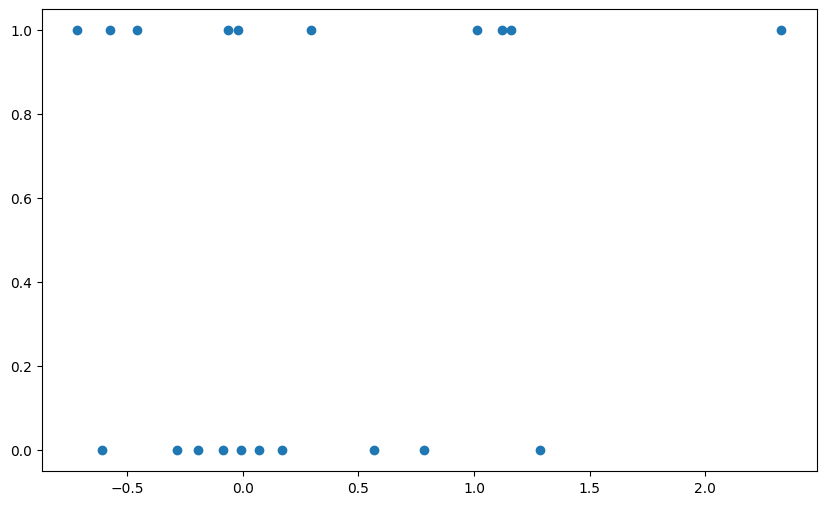

In [ ]:
plt.figure(figsize= (10,6))
plt.scatter(x = X_test['x1'], y = y_pred)
plt.title("Visión de x_1 frente lo predicho")
plt.show()


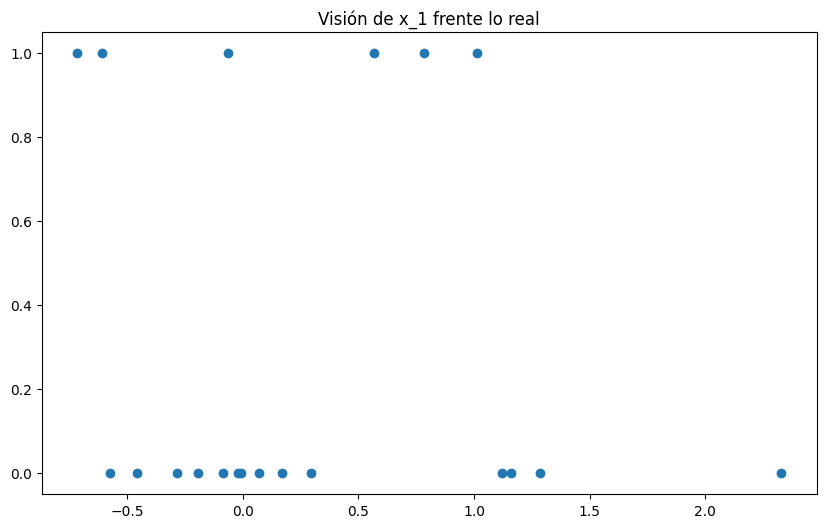

In [32]:
plt.figure(figsize= (10,6))
plt.scatter(x = X_test['x1'], y = y_test)
plt.title("Visión de x_1 frente lo real")
plt.show()

# Voy a practicar con la Naive-Bayes

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [2]:
# Cargar el dataset MNIST
X, y = fetch_openml('mnist_784', version=1, return_X_y=True, as_frame=False, parser='auto')
y = y.astype(int)  # Convertir las etiquetas a enteros


In [3]:
# Paso 0 
# Binarizar los datos
X_binario = np.where(X>127.5, 1, 0)

# Dividir los datos en train test split
X_train, X_test, y_train, y_test = train_test_split(X_binario, y, test_size =0.2, random_state=0)

In [4]:
# Paso 1 
# Preparar un afunción que permita sacar los datos que pertenecen a una clase

def extraer_clase (X, y, clase):
    mask = y == c
    X_c = X[mask]
    return X_c

In [9]:
# Paso 2
# Preparo una función que me permita sacar los priors. Nc/N

def extraer_priors(y):
    total = len(y)
    i, c = np.unique(y, return_counts= True)
    priors = c/total
    return priors


# Preparo una función que me permita sacar los thetas. N_ic/Nc

def extaer_thetas(X_c):
    N_c = X_c.shape(0)
    N_ic = X_c.sum(axis=0)
    thetas = (N_ic+1)/(N_c+2)
    return thetas

In [ ]:
# Paso 3. 
# Tenemos que crear una función que haga el entrenamiento. Tiene que devolver los priors y las thetas
def fit_bayes (X,y):
    n_samples, p = X.shape
    priors = extraer_priors(y)
    clases, total = np.unique(y, return_counts= True)
    n_clases = len(clases)
    thetas_estimados = np.zeros(p, n_clases)
    for i, c in enumerate (range(clases)):
        X_c = extraer_clase(X, y, clase=c)
        thetas_estimados[:,i] = extaer_thetas(X_c)


    return priors, thetas_estimados

In [ ]:
# Paso 4. 
# Predicción

def predecir_bayes (X, priors, thetas):
    log_probs = np.zeros ((n_samples, n_clases))
    n_samples = X.shape(0)
    clases, count = np.unique(y, return_counts= True)
    n_clases = len(clases)
    for i in range(n_samples):
        x = X[i]
        for c in range(n_clases):
        log_priors = np.log(priors[c])
        log_likehood = x*np.log(thetas[:,c]) + (1-x)*(1-np.log(thetas[:,c]))
        log_likehood_sum = np.sum(log_likehood1)
        log_total = log_priors + log_likehood_sum
        log_probs [i,c] = log_total
    
    predicted_classes = np.argmax(log_probs, axis=1)

    return predicted_classes
    

